# <span style="color: #1F1DB5;">SPRINT 5 – Análisis Estadístico de Datos

# <span style="color: #1F1DB5;">Notebook 2 – Ejercicios de Probabilidades: Bayes, Conjuntos y Entrevistas

## Ficha de la sesión

| Campo | Detalle |
|---|---|
| Programa | Data Science |
| Sprint / sesión | Sprint 5 · Clase 2 |
| Tema | Ejercicios de Probabilidades |
| Audiencia | Tutor |
| Tipo de sesión | práctica guiada |
| Duración de referencia | 120 minutos, incluida práctica, validación y cierre |
| Última actualización | 2026-08-19 |



## Prerrequisitos y preparación

- **Conceptuales:** Python y Pandas básicos; lectura de tablas y operaciones aritméticas.
- **Técnicos:** Python 3.11 o entorno compatible; instalar dependencias desde `../../requirements.txt`.
- **Archivos y red:** usa solo rutas relativas. Cuando haya una operación externa, revisa su nota de contingencia antes de clase.
- **Reproducibilidad:** usa la semilla de referencia `42` en cualquier operación aleatoria y documenta excepciones.


## Resultado esperado y evidencia

**Entregable:** Resolución analítica y simulada de problemas de probabilidad.

**Criterio de aceptación principal:** Declara la semilla 42, contrasta simulación con teoría e interpreta la diferencia.

La evidencia debe quedar dentro del notebook: código o procedimiento, comprobación del resultado y una interpretación breve.


## Ruta de trabajo e instrucciones de uso

1. Lee la pregunta guía, los objetivos y el entregable antes de ejecutar código.
2. Ejecuta las celdas en orden; si cambias una definición, reinicia el kernel y usa **Run All**.
3. En cada actividad sigue: **propósito → intento → validación → interpretación**.
4. Ejecuta primero en kernel limpio; guía la discusión antes de mostrar soluciones o criterios esperados.
5. Registra cualquier supuesto, fuente externa o cambio de datos.

> **Control obligatorio de esta clase:** Declara la semilla 42, contrasta simulación con teoría e interpreta la diferencia.


## <span style="color: #2826DE;">Objetivos de Aprendizaje

- Detectar **valores extremos** usando los límites teóricos de los bigotes de un boxplot
- Resolver problemas de **probabilidad y valor esperado** del tipo entrevista de trabajo
- Comprender la diferencia entre **estadística frecuentista y bayesiana**
- Aplicar el **Teorema de Bayes** con su demostración simplificada
- Resolver el **Problema de Monty Hall** como aplicación de Bayes

### <span style="color: #2772F2;">Agenda (2 horas)

| Tema | Duración |
|---|---|
Introducción + Pregunta guía | 10 min |
Valores extremos con boxplot: límites teóricos | 20 min |
Ejercicio de entrevista: probabilidad y esperanza | 25 min |
Estadística frecuentista vs bayesiana | 15 min |
Teorema de Bayes y Monty Hall | 25 min |
Actividad práctica – Breakout Rooms | 20 min |
Cierre y Kahoot | 5 min |

## <span style="color: #2826DE;">Pregunta Guía

### ¿Cómo pensar como estadísticos al resolver **problemas del mundo real**?

<img src="../../Images/S3_DS_statistics.jpg" width="600">

## <span style="color: #2826DE;">Valores extremos con boxplot (20 mins)

Antes de detectar outliers con codigo, necesitamos entender la formula matematica detras de los bigotes de un boxplot. Los limites IQR son el estandar de la industria para identificar valores extremos de forma objetiva.

Q1=43.9, Q3=55.0, IQR=11.1
Limite inferior: 27.2
Limite superior: 71.7
Outliers: [23.80254896 95.         98.          2.          5.        ]


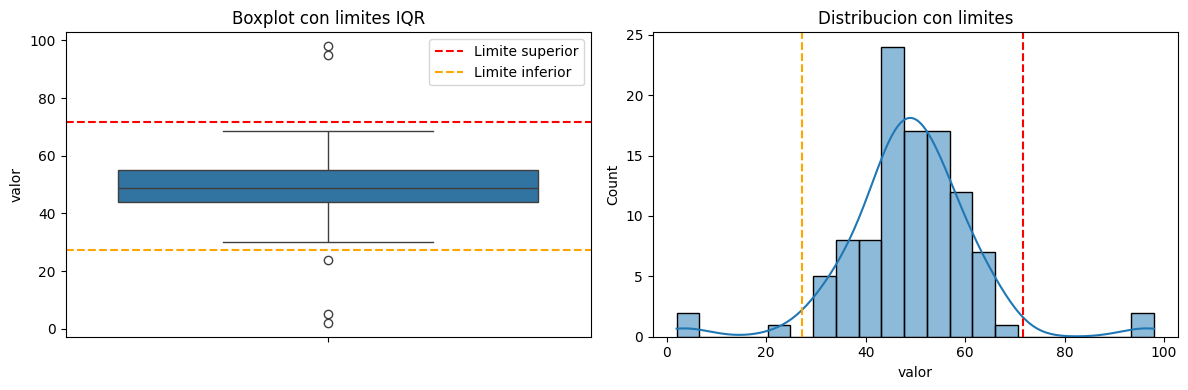

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset de ejemplo
np.random.seed(42)
datos = np.concatenate([np.random.normal(50, 10, 100), [95, 98, 2, 5]])
df = pd.DataFrame({"valor": datos})

# Calcular limites IQR
Q1 = df["valor"].quantile(0.25)
Q3 = df["valor"].quantile(0.75)
IQR = Q3 - Q1
limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR

print(f"Q1={Q1:.1f}, Q3={Q3:.1f}, IQR={IQR:.1f}")
print(f"Limite inferior: {limite_inf:.1f}")
print(f"Limite superior: {limite_sup:.1f}")

outliers = df[(df["valor"] < limite_inf) | (df["valor"] > limite_sup)]
print(f"Outliers: {outliers['valor'].values}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y="valor", data=df, ax=axes[0])
axes[0].axhline(limite_sup, color='red', linestyle='--', label='Limite superior')
axes[0].axhline(limite_inf, color='orange', linestyle='--', label='Limite inferior')
axes[0].set_title("Boxplot con limites IQR")
axes[0].legend()

sns.histplot(df["valor"], kde=True, ax=axes[1])
axes[1].axvline(limite_sup, color='red', linestyle='--')
axes[1].axvline(limite_inf, color='orange', linestyle='--')
axes[1].set_title("Distribucion con limites")
plt.tight_layout()
plt.show()

### Preguntas:

- ¿Cuántos outliers encontraste? Coinciden con los valores que agregamos artificialmente (95, 98, 2, 5)?

- ¿Por qué el limite superior no es exactamente 95? ¿Qué factores lo afectan?

- En un dataset real, ¿cómo decidirás si un outlier es un error o un valor valido?

## <span style="color: #2826DE;">Ejercicio de entrevista: probabilidad y esperanza (25 mins)

#### Criterios de logro

- La respuesta atiende todos los elementos de la consigna.
- El resultado incluye una comprobación observable, no solo código o una afirmación.
- La conclusión explica qué significa el resultado y menciona al menos un supuesto.
- **Control específico:** Declara la semilla 42, contrasta simulación con teoría e interpreta la diferencia.

> **Nota para tutor:** pide una predicción antes de ejecutar, valida el criterio en vivo y comenta al menos un error frecuente.


### <span style="color: #2772F2;">Problema clasico de entrevista

**Problema:** Tienes una moneda justa. Si sale cara ganas $3, si sale cruz pierdes $1.

1. ¿Cuál es el valor esperado de cada lanzamiento?
2. Si juegas 100 veces, ¿cuánto esperas ganar/perder?
3. ¿Es un juego favorable para ti?

Este tipo de problema aparece frecuentemente en entrevistas de trabajo para posiciones de Data Science. La clave es calcular el valor esperado correctamente y luego simular para verificar. Intenta resolverlo tu mismo antes de ver la solución.

Valor esperado por lanzamiento: $1.0
En 100 lanzamientos: $100.0
El juego es favorable para ti


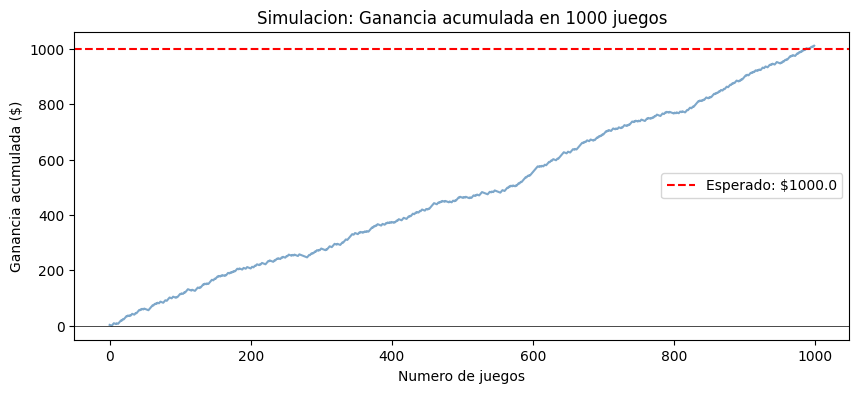

Ganancia real despues de 1000 juegos: $1012


In [7]:
# Solucion paso a paso
# Resultados posibles
resultados = {"Cara": 3, "Cruz": -1}
probabilidades = {"Cara": 0.5, "Cruz": 0.5}

# Valor esperado
E = sum(resultados[r] * probabilidades[r] for r in resultados)
print(f"Valor esperado por lanzamiento: ${E}")
print(f"En 100 lanzamientos: ${E * 100}")
print(f"El juego es {'favorable' if E > 0 else 'desfavorable'} para ti")

# Simulacion
np.random.seed(42)
n_juegos = 1000
ganancias_acumuladas = []
total = 0

for _ in range(n_juegos):
    resultado = np.random.choice([3, -1], p=[0.5, 0.5])
    total += resultado
    ganancias_acumuladas.append(total)

plt.figure(figsize=(10, 4))
plt.plot(ganancias_acumuladas, color='steelblue', alpha=0.7)
plt.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
plt.axhline(y=E * n_juegos, color='red', linestyle='--', label=f'Esperado: ${E*n_juegos}')
plt.xlabel('Numero de juegos')
plt.ylabel('Ganancia acumulada ($)')
plt.title('Simulacion: Ganancia acumulada en 1000 juegos')
plt.legend()
plt.show()
print(f"Ganancia real despues de {n_juegos} juegos: ${total}")

Preguntas:

- El valor esperado es positivo. ¿Significa eso que siempre ganarás dinero?

- En la simulacion, hay momentos donde la ganancia acumulada es negativa. ¿Por qué?

- ¿Si el valor esperado fuera negativo, jugarías igual? ¿Por qué?

## <span style="color: #2826DE;">Estadistica frecuentista vs bayesiana (15 mins)

### <span style="color: #2772F2;">Dos filosofias de la estadística

| '| Frecuentista | Bayesiana |
|---|---|---|
| **Probabilidad** | Frecuencia a largo plazo | Grado de creencia |
| **Parametros** | Fijos, desconocidos | Variables aleatorias |
| **Datos** | Aleatorios | Fijos (observados) |
| **Resultado** | p-valor, intervalos de confianza | Distribucion posterior |
| **Conocimiento previo** | No se usa | Se incorpora (prior) |

**Ejemplo:** Probabilidad de que llueva manana
- **Frecuentista**: basado en historico de dias similares
- **Bayesiana**: historico + lo que ves en el cielo ahora

## <span style="color: #2826DE;">Teorema de Bayes y Monty Hall (25 mins)

### <span style="color: #2772F2;">Teorema de Bayes

$$P(A|B) = \frac{P(B|A) \cdot P(A)}{P(B)}$$

**Ejemplo medico:** Una enfermedad afecta al 1% de la población. Un test tiene 95% de sensibilidad y 90% de especificidad. Si el test es positivo, ¿cuál es la probabilidad real de tener la enfermedad?

El Teorema de Bayes parece complicado pero la idea es simple: actualizar nuestra creencia inicial (prior) con nueva evidencia para obtener una creencia actualizada (posterior). El ejemplo medico es clasico porque el resultado sorprende a la mayoria de las personas.

In [8]:
# Aplicacion del Teorema de Bayes
P_enfermedad = 0.01        # Prior: 1% tiene la enfermedad
P_positivo_dado_enfermo = 0.95   # Sensibilidad
P_positivo_dado_sano = 0.10      # 1 - especificidad
P_sano = 1 - P_enfermedad

# P(positivo) = P(positivo|enfermo)*P(enfermo) + P(positivo|sano)*P(sano)
P_positivo = (P_positivo_dado_enfermo * P_enfermedad +
              P_positivo_dado_sano * P_sano)

# Bayes: P(enfermo|positivo)
P_enfermo_dado_positivo = (P_positivo_dado_enfermo * P_enfermedad) / P_positivo

print("=== Diagnostico medico con Bayes ===")
print(f"Prevalencia de la enfermedad: {P_enfermedad:.1%}")
print(f"Sensibilidad del test: {P_positivo_dado_enfermo:.1%}")
print(f"Especificidad del test: {1-P_positivo_dado_sano:.1%}")
print(f"\nP(test positivo): {P_positivo:.3%}")
print(f"P(enfermo | test positivo): {P_enfermo_dado_positivo:.1%}")
print(f"\nSorpresa: aunque el test es positivo, solo hay {P_enfermo_dado_positivo:.1%} de probabilidad real!")

=== Diagnostico medico con Bayes ===
Prevalencia de la enfermedad: 1.0%
Sensibilidad del test: 95.0%
Especificidad del test: 90.0%

P(test positivo): 10.850%
P(enfermo | test positivo): 8.8%

Sorpresa: aunque el test es positivo, solo hay 8.8% de probabilidad real!


Preguntas:

- ¿El resultado te sorprende? ¿Por qué la probabilidad real es tan baja si el test es tan preciso?

- ¿Qué pasaria si la prevalencia de la enfermedad fuera del 10% en lugar del 1%?

- ¿Cómo se relaciona este resultado con los falsos positivos en modelos de ML?

### <span style="color: #2772F2;">El Problema de Monty Hall

<img src="../../Images/S3_DS_monty_hall.jpg" width="600">

**Reglas:**
1. Hay 3 puertas: detras de una hay un carro, detras de las otras dos hay cabras
2. Eliges una puerta
3. El presentador (que sabe donde esta el carro) abre una puerta con cabra
4. Te ofrecen cambiar de puerta

**Pregunta:** ¿Deberías cambiar de puerta?

El Problema de Monty Hall es famoso porque la respuesta correcta va en contra de la intuicion de la mayoria de las personas. Incluso matematicos y estadisticos famosos se equivocaron cuando se publico por primera vez. Vamos a simularlo para ver la respuesta con nuestros propios ojos.

=== Problema de Monty Hall ===
Simulaciones: 10,000

Estrategia CAMBIAR:
  Victorias: 6,668 (66.7%)

Estrategia QUEDARSE:
  Victorias: 3,332 (33.3%)

Conclusion: SIEMPRE deberias CAMBIAR de puerta!
Cambiar da ~66.7% de probabilidad vs ~33.3% quedandose


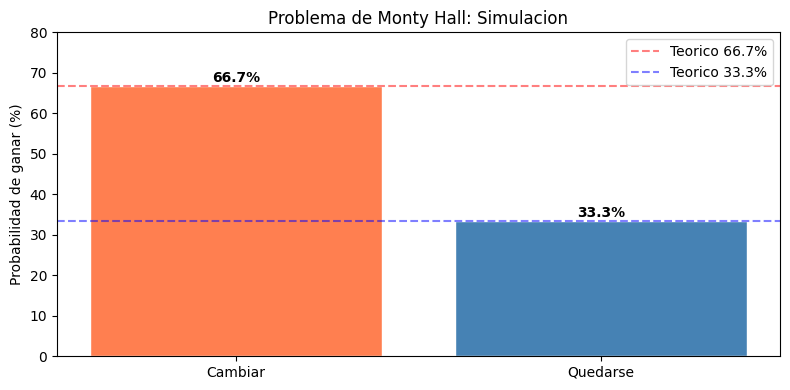

In [9]:
# Simulacion del Problema de Monty Hall
np.random.seed(42)
n_simulaciones = 10000

gana_cambiando = 0
gana_quedandose = 0

for _ in range(n_simulaciones):
    # Posicion del carro (0, 1, o 2)
    carro = np.random.randint(0, 3)
    
    # Eleccion inicial del jugador
    eleccion = np.random.randint(0, 3)
    
    # Monty abre una puerta con cabra (no la del carro ni la elegida)
    puertas_disponibles = [p for p in range(3) if p != eleccion and p != carro]
    monty_abre = np.random.choice(puertas_disponibles)
    
    # Estrategia 1: CAMBIAR
    nueva_eleccion = [p for p in range(3) if p != eleccion and p != monty_abre][0]
    if nueva_eleccion == carro:
        gana_cambiando += 1
    
    # Estrategia 2: QUEDARSE
    if eleccion == carro:
        gana_quedandose += 1

print("=== Problema de Monty Hall ===")
print(f"Simulaciones: {n_simulaciones:,}")
print(f"\nEstrategia CAMBIAR:")
print(f"  Victorias: {gana_cambiando:,} ({gana_cambiando/n_simulaciones:.1%})")
print(f"\nEstrategia QUEDARSE:")
print(f"  Victorias: {gana_quedandose:,} ({gana_quedandose/n_simulaciones:.1%})")
print(f"\nConclusion: SIEMPRE deberias CAMBIAR de puerta!")
print(f"Cambiar da ~66.7% de probabilidad vs ~33.3% quedandose")

# Visualizacion
fig, ax = plt.subplots(figsize=(8, 4))
estrategias = ['Cambiar', 'Quedarse']
victorias = [gana_cambiando/n_simulaciones, gana_quedandose/n_simulaciones]
colores = ['coral', 'steelblue']

bars = ax.bar(estrategias, [v*100 for v in victorias], color=colores, edgecolor='white')
ax.axhline(y=66.7, color='red', linestyle='--', alpha=0.5, label='Teorico 66.7%')
ax.axhline(y=33.3, color='blue', linestyle='--', alpha=0.5, label='Teorico 33.3%')
ax.set_ylabel('Probabilidad de ganar (%)')
ax.set_title('Problema de Monty Hall: Simulacion')
ax.set_ylim(0, 80)
ax.legend()

for bar, v in zip(bars, victorias):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{v:.1%}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

Preguntas:

- ¿La simulación confirma que cambiar de puerta es mejor? ¿Por cuánto?

- ¿Por qué cambiar de puerta da 66.7% de probabilidad? Intenta explicarlo intuitivamente.

- ¿Si hubiera 100 puertas y Monty abriera 98, seguirías cambiando? ¿Por qué?

## <span style="color: #2826DE;">Actividad practica - Breakout Rooms (20 mins)

#### Criterios de logro

- La respuesta atiende todos los elementos de la consigna.
- El resultado incluye una comprobación observable, no solo código o una afirmación.
- La conclusión explica qué significa el resultado y menciona al menos un supuesto.
- **Control específico:** Declara la semilla 42, contrasta simulación con teoría e interpreta la diferencia.

> **Nota para tutor:** pide una predicción antes de ejecutar, valida el criterio en vivo y comenta al menos un error frecuente.


### <span style="color: #aa0808;">En esta ocasión, quien compartira resultados será: (Giremos la ruleta)

### Ejercicio 1 - Outliers con IQR

Dado el dataset de pinguinos, detecta outliers en `bill_length_mm` usando IQR.
Visualiza con boxplot y reporta cuantos hay.

#### Criterios de logro

- La respuesta atiende todos los elementos de la consigna.
- El resultado incluye una comprobación observable, no solo código o una afirmación.
- La conclusión explica qué significa el resultado y menciona al menos un supuesto.
- **Control específico:** Declara la semilla 42, contrasta simulación con teoría e interpreta la diferencia.

> **Nota para tutor:** pide una predicción antes de ejecutar, valida el criterio en vivo y comenta al menos un error frecuente.


In [10]:
import pandas as pd
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df = pd.read_csv(url)
# Tu codigo aqui


### Ejercicio 2 - Bayes aplicado

Un filtro de spam tiene 99% de precision para detectar spam y 1% de falsos positivos.
El 20% de los emails son spam.

Si un email es marcado como spam, cual es la probabilidad real de que sea spam?

#### Criterios de logro

- La respuesta atiende todos los elementos de la consigna.
- El resultado incluye una comprobación observable, no solo código o una afirmación.
- La conclusión explica qué significa el resultado y menciona al menos un supuesto.
- **Control específico:** Declara la semilla 42, contrasta simulación con teoría e interpreta la diferencia.

> **Nota para tutor:** pide una predicción antes de ejecutar, valida el criterio en vivo y comenta al menos un error frecuente.


In [11]:
# Tu codigo aqui


## <span style="color: #2826DE;">Cierre y Kahoot (5 mins)

Kahoot - Preguntas sugeridas

1️⃣ ¿En el Problema de Monty Hall, deberías cambiar de puerta?

- No, la probabilidad es la misma en ambas puertas
- Sí, cambiar aumenta la probabilidad a 66.7% ✅
- No, es mejor quedarse con la elección original
- Solo si el presentador te lo sugiere


2️⃣ ¿Qué es el Teorema de Bayes?

- Una fórmula para calcular promedios
- Una forma de actualizar probabilidades con nueva evidencia ✅
- Un método para detectar outliers
- Una técnica de visualización de datos


3️⃣ ¿Cuál es la diferencia entre estadística frecuentista y bayesiana?

- La frecuentista usa más datos
- La bayesiana incorpora conocimiento previo (prior) ✅
- La bayesiana es más antigua
- La frecuentista es más precisa


4️⃣ ¿Qué son los outliers según el método IQR?

- Valores fuera de Q1 - 1.5 × IQR o Q3 + 1.5 × IQR ✅
- Valores iguales a la media
- Valores en el primer cuartil
- Valores entre Q1 y Q3


5️⃣ Si el valor esperado de un juego es positivo, ¿qué significa?

- En promedio, a largo plazo, ganarás dinero ✅
- Siempre ganarás dinero
- Nunca perderás dinero
- El juego es ilegal


6️⃣ En el ejemplo médico con Bayes, ¿por qué la probabilidad real es tan baja?

- Porque el test es poco preciso
- Porque la enfermedad es muy rara (baja prevalencia) ✅
- Porque la fórmula de Bayes está mal aplicada
- Porque los datos son incorrectos


7️⃣ ¿Qué fórmula usan los bigotes de un boxplot para detectar outliers?

- Media ± 2 desviaciones estándar
- Q1 - 1.5 × IQR y Q3 + 1.5 × IQR ✅
- Percentil 5 y percentil 95
- Mínimo y máximo de los datos


8️⃣ ¿Qué es el valor esperado?

- El valor más probable de ocurrir
- El promedio ponderado de todos los resultados posibles ✅
- El valor máximo posible
- La mediana de la distribución

## Cierre, límites y siguientes pasos

### Síntesis

La clase de **Ejercicios de Probabilidades** conecta los conceptos con una evidencia reproducible. El trabajo se considera completo cuando produce **resolución analítica y simulada de problemas de probabilidad.** y satisface el control técnico definido al inicio.

### Limitaciones que deben declararse

- Los resultados dependen del alcance y la calidad de los datos o ejemplos usados.
- Una ejecución correcta no demuestra por sí sola que el resultado generalice a otros contextos.
- Las decisiones de modelado, limpieza o comunicación deben justificarse según el problema.

### Lista de salida

- [ ] Respondí la pregunta guía con evidencia.
- [ ] Validé el resultado con el criterio de logro: Declara la semilla 42, contrasta simulación con teoría e interpreta la diferencia.
- [ ] Documenté supuestos, límites y decisiones.
- [ ] Dejé rutas portables, sin credenciales ni información privada.

Antes de publicar, usa Restart Kernel and Run All y conserva únicamente outputs breves que ayuden a verificar el resultado esperado.

### Ayuda y recursos

- Revisa los ejemplos y el glosario de esta clase antes de cambiar el enfoque.
- Lleva dudas concretas y el mensaje de error completo a los canales de soporte u office hours.
- Continúa con la siguiente clase del sprint y reutiliza este entregable como evidencia de aprendizaje.
